# 04 · Evaluation: frozen models on later data and on other collectors' data

This notebook tests the frozen models on three datasets they never saw: later PhreshPhish data and two datasets from other collectors. It compares them with two baselines, splits every result three ways to find where it fails, and writes `reports/metrics.json` and `reports/results.md`.

The models were frozen in notebooks 02 and 03. Nothing here changes them: thresholds and calibrators are read from `models/*_operating.json`, which were built from validation data only. No result here was used to adjust a model.

**Scorers**

| Scorer | What it is |
|---|---|
| Model A: LightGBM | 31 lexical features, main track (query string removed). Deployed |
| Model B: character CNN | Characters of the URL, main track. Deployed |
| Comparison: LightGBM on full URLs | Same training rows as Model A, query string kept. Shows what the query-string artefact is worth |
| Baseline: LightGBM trained on PhiUSIIL | The benchmark trap |
| Baseline: one-line template rule | "Legitimate if the URL is `https://www.<host>/`, otherwise phishing". No learning |

**Test sets**

| Test set | What it tests | Caveat |
|---|---|---|
| PhreshPhish evaluation sample (50,000 pinned rows) | **Later in time:** every row was collected after every training row | Same collector as the training data |
| Wangchuk | **A different source** | Its phishing URLs predate the training data; its presumed-benign class covers 547 registered domains |
| Ariyadasa et al. | **A different source** (second check) | Collected in 2020-21, about three years before the training data |

**Metrics.** PR-AUC and ROC-AUC measure ranking. *Detection at 0.1% FPR* is the best detection rate a test set allows at a 0.1% false-positive rate, and *FPR at 95% detection* the false-positive rate needed to catch 95% of its phishing. The operating results use the two **frozen** thresholds: **block** (set on validation to flag at most 0.1% of legitimate URLs) and **warn** (set on validation to catch at least 95% of phishing). Every number has a 95% interval from 1,000 bootstrap resamples.

**Why not accuracy.** Accuracy is not used to judge the models. It depends on each test set's class mix (36% to 46% phishing here, far above real traffic), and at a realistic phishing rate of 0.1% a scorer that allowed every link would be 99.9% accurate while catching nothing. Notebook 01 showed the same trap from the other side: a one-line rule with no learning is right for 99.73% of PhiUSIIL. So the project reports ranking quality that does not depend on the class mix (ROC-AUC), detection at a fixed, low false-positive rate (the cost of a false alarm decides whether a tool stays switched on), and precision recomputed at realistic phishing rates (section 6).

**Calibrated scores are not real-world probabilities**, and no class mix here is a real-world rate; section 6 converts results to realistic base rates.

In [1]:
import sys
import warnings

# Progress bars need ipywidgets, which this environment does not install; the warning is noise.
warnings.filterwarnings("ignore", message="IProgress not found")
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import data as D
from src import evaluate as E
from src import features as F
from src import models as M

pd.set_option("display.width", 250, "display.max_colwidth", 60)
D.set_seeds(D.SEED)

from src import report

MAIN = report.MAIN
CONTEXT = {"phreshphish_val": "PhreshPhish validation (thresholds were set here)",
           "phiusiil_test": "PhiUSIIL test split"}

## 1. Load the frozen models and check their hashes

In [2]:
recorded = M.load_json(M.MODELS_DIR / "hashes.json")
check = pd.DataFrame({
    name: {"recorded": info["sha256"][:16] + "...",
           "matches the file on disk": M.sha256_file(ROOT / name if "/" in name else M.MODELS_DIR / name) == info["sha256"]}
    for name, info in recorded.items()
}).T
display(check)
assert check["matches the file on disk"].all(), "A model file differs from the one that was trained"

scorers = E.load_scorers()
thresholds = pd.DataFrame({
    s["label"]: {"block: raw score": s["operating"]["thresholds"]["block"]["raw_score"],
                 "warn: raw score": s["operating"]["thresholds"]["warn"]["raw_score"],
                 "block: validation FPR": s["operating"]["thresholds"]["block"].get("validation_fpr"),
                 "block: validation detection": s["operating"]["thresholds"]["block"].get("validation_tpr"),
                 "warn: validation FPR": s["operating"]["thresholds"]["warn"].get("validation_fpr"),
                 "warn: validation detection": s["operating"]["thresholds"]["warn"].get("validation_tpr")}
    for s in scorers.values()
}).T
thresholds.style.format({"block: raw score": "{:.3f}", "warn: raw score": "{:.3f}", "block: validation FPR": "{:.3%}",
                         "block: validation detection": "{:.1%}", "warn: validation FPR": "{:.1%}",
                         "warn: validation detection": "{:.1%}"}, na_rep="n/a")

,recorded,matches the file on disk
models/cnn.onnx,2aa57f09d042365b...,True
models/cnn_operating.json,d09aa2669bf3df7b...,True
models/lgbm.txt,6ef2b4b710b5834e...,True
models/lgbm_full_urls.txt,10fccf36343c9faa...,True
models/lgbm_full_urls_operating.json,05e62db8553bc598...,True
models/lgbm_operating.json,b8a5f87bf762df64...,True
models/lgbm_phiusiil.txt,08ee26e8bfbf4b64...,True
models/lgbm_phiusiil_operating.json,63b1279b6012fb75...,True
models/review_operating.json,cdd9590c15abcc8f...,True
src/features.py,1d9f941f40432f0a...,True


,block: raw score,warn: raw score,block: validation FPR,block: validation detection,warn: validation FPR,warn: validation detection
Model A: LightGBM,4.434,-5.422,0.100%,16.3%,65.9%,95.0%
Model B: character CNN,4.470,-11.893,0.100%,44.2%,71.5%,95.0%
Comparison: LightGBM on full URLs,4.419,-5.517,0.100%,25.4%,65.9%,95.0%
Baseline: LightGBM trained on PhiUSIIL,2.425,1.288,0.099%,93.2%,0.4%,95.0%
Baseline: one-line template rule,0.500,0.500,n/a,n/a,n/a,n/a


The thresholds above are the ones every result below uses. The PhiUSIIL baseline's thresholds come from PhiUSIIL's own validation split. The template rule has a single operating point.

## 2. Score every test set

Each dataset is scored by every scorer. For the credibility splits, three facts are attached to each URL: whether it is a bare homepage, whether its registered domain occurs in the PhreshPhish training or validation data, and whether the URL as shipped had a query string.

In [3]:
train_domains = E.registered_domains(pd.concat([D.load_processed("phreshphish_train")[["url"]],
                                                D.load_processed("phreshphish_val")[["url"]]]))
frames, scores, groups = {}, {}, {}
for key in list(MAIN) + list(CONTEXT):
    frames[key] = D.load_processed(key)
    scores[key] = E.score_frame(frames[key], scorers)
    groups[key] = E.add_groups(frames[key], train_domains)
    print(f"{key:18s} {len(frames[key]):>7,} rows scored by {scores[key].shape[1]} scorers")

phreshphish_eval    50,000 rows scored by 5 scorers


wangchuk            98,085 rows scored by 5 scorers


ariyadasa           76,169 rows scored by 5 scorers


phreshphish_val     76,009 rows scored by 5 scorers


phiusiil_test       34,904 rows scored by 5 scorers


In [4]:
results = {}
for key in MAIN:
    external = key in ("wangchuk", "ariyadasa")
    results[key] = E.evaluate_dataset(frames[key], scores[key], groups[key], scorers, splits=True,
                                      domain_fpr=external, pages_only=(key == "wangchuk"))
for key in CONTEXT:
    results[key] = E.evaluate_dataset(frames[key], scores[key], groups[key], scorers, splits=False)

eval_phishing = frames["phreshphish_eval"][frames["phreshphish_eval"]["label"] == 1]
robust = E.robustness(eval_phishing, scorers)

metrics = {
    "label_convention": "1 = phishing, 0 = legitimate",
    "notes": {
        "main_track": "query string and fragment removed from every URL before scoring",
        "thresholds": "frozen; chosen on PhreshPhish validation only (PhiUSIIL validation for the PhiUSIIL baseline)",
        "intervals": f"95% percentile intervals from {E.N_BOOTSTRAP} bootstrap resamples of rows (seed {E.BOOTSTRAP_SEED}); "
                     "false-positive rates by domain resample registered domains",
        "calibration": "calibrated scores are not real-world probabilities",
        "domain_seen": "registered domain occurs in the PhreshPhish training or validation data",
    },
    "scorers": {name: {"label": s["label"], "role": s["role"], "thresholds": s["operating"]["thresholds"],
                       "training": {k: v for k, v in s["operating"].get("training", {}).items()
                                    if k in ("fit_rows", "validation_roc_auc", "validation_pr_auc", "n_rounds", "epochs_run",
                                             "run_to_run_variation", "onnx_parity", "tuning")}}
                for name, s in scorers.items()},
    "datasets": {key: {"title": title, "role": "test" if key in MAIN else "context", "rows": int(len(frames[key])),
                       **D.class_counts(frames[key])} for key, title in {**MAIN, **CONTEXT}.items()},
    "results": results,
    "robustness": robust,
    "model_hashes": {name: recorded[name] for name in E.EVALUATED_FILES},
}
_, status = E.write_metrics(metrics)
metrics = M.load_json(E.REPORTS_DIR / "metrics.json")      # everything below is read from the saved file
R = metrics["results"]
print("Saved reports/metrics.json.", status)

Saved reports/metrics.json. The saved post hoc results were dropped because the evaluation changed; run notebooks/05_post_hoc.ipynb again.


## 3. Headline results

One row per test set and scorer. Intervals in brackets.

In [5]:
headline = E.headline_table(R, MAIN)
headline

ROC-AUC               PR-AUC Detection at 0.1% FPR  FPR at 95% detection   Block: detection            Block: FPR       Warn: detection          Warn: FPR  \
Dataset                     Scorer                                                                                                                                                                                                           
PhreshPhish, later in time  Model A: LightGBM                       0.957 (0.955-0.959)  0.957 (0.956-0.959)     36.8% (34.1-40.1)     20.9% (19.9-21.9)  33.5% (32.9-34.1)     0.07% (0.04-0.10)     98.9% (98.8-99.0)  66.9% (66.3-67.5)   
                            Model B: character CNN                  0.973 (0.971-0.974)  0.976 (0.975-0.977)     52.7% (48.5-57.6)     13.0% (11.9-14.3)  55.6% (55.0-56.2)     0.13% (0.09-0.18)     99.1% (99.0-99.2)  72.8% (72.2-73.3)   
                            Comparison: LightGBM on full URLs       0.967 (0.965-0.968)  0.969 (0.967-0.970)     48.4% (41.5-53.1)     17.5% (16.3-18.4)  50.1% (49.5-50.7)     0.12% (0.08-0.16)     98.9% (98.8-99.1)  67.1% (66.5-67.6)   
                            Baseline: LightGBM trained on PhiUSIIL  0.359 (0.353-0.364)  0.451 (0.445-0.457)        3.0% (2.7-3.3)     95.3% (95.0-95.5)  73.5% (73.0-74.1)  93.72% (93.46-94.00)     76.7% (76.1-77.2)  93.8% (93.5-94.1)   
                            Baseline: one-line template rule        0.487 (0.485-0.489)  0.451 (0.446-0.455)        0.0% (0.0-0.0)  100.0% (100.0-100.0)  92.8% (92.5-93.2)  95.41% (95.18-95.65)     92.8% (92.5-93.2)  95.4% (95.2-95.6)   
Wangchuk, different source  Model A: LightGBM                       0.922 (0.921-0.924)  0.876 (0.873-0.879)     11.1% (10.7-12.0)     27.6% (27.2-28.3)  45.5% (45.0-46.0)     3.26% (3.11-3.40)  100.0% (100.0-100.0)  79.1% (78.8-79.4)   
                            Model B: character CNN                  0.953 (0.952-0.954)  0.925 (0.923-0.927)     14.2% (12.7-15.6)     21.5% (20.9-22.1)  81.5% (81.1-81.8)     7.66% (7.46-7.88)  100.0% (100.0-100.0)  87.7% (87.4-87.9)   
                            Comparison: LightGBM on full URLs       0.868 (0.866-0.870)  0.763 (0.758-0.767)        5.3% (4.7-6.3)     34.1% (33.7-34.5)  48.2% (47.7-48.8)  11.05% (10.81-11.31)  100.0% (100.0-100.0)  80.0% (79.7-80.4)   
                            Baseline: LightGBM trained on PhiUSIIL  0.434 (0.430-0.438)  0.379 (0.375-0.383)        0.1% (0.1-0.1)     99.2% (99.2-99.3)  86.9% (86.5-87.2)  99.02% (98.95-99.10)     90.1% (89.7-90.4)  99.1% (99.0-99.1)   
                            Baseline: one-line template rule        0.493 (0.492-0.494)  0.394 (0.391-0.397)        0.0% (0.0-0.0)     99.6% (99.5-99.6)  98.2% (98.1-98.3)  99.58% (99.53-99.63)     98.2% (98.1-98.3)  99.6% (99.5-99.6)   
Ariyadasa, different source Model A: LightGBM                       0.926 (0.924-0.928)  0.878 (0.874-0.882)     11.9% (10.5-13.7)     32.5% (31.7-33.2)  17.7% (17.2-18.1)     0.19% (0.15-0.23)    99.9% (99.9-100.0)  80.5% (80.2-80.9)   
                            Model B: character CNN                  0.963 (0.962-0.965)  0.938 (0.936-0.941)     19.3% (15.6-21.9)     17.5% (16.7-18.1)  46.9% (46.3-47.5)     0.77% (0.69-0.85)  100.0% (100.0-100.0)  85.2% (84.9-85.5)   
                            Comparison: LightGBM on full URLs       0.905 (0.903-0.907)  0.801 (0.796-0.807)        2.7% (2.2-3.3)     33.4% (32.6-34.2)  29.1% (28.6-29.7)     3.75% (3.59-3.92)    99.9% (99.9-100.0)  80.8% (80.5-81.2)   
                            Baseline: LightGBM trained on PhiUSIIL  0.620 (0.615-0.624)  0.511 (0.505-0.518)        1.5% (1.3-1.7)     91.1% (90.9-91.4)  93.1% (92.8-93.4)  90.98% (90.73-91.24)     94.3% (94.1-94.6)  91.1% (90.8-91.3)   
                            Baseline: one-line template rule        0.522 (0.521-0.524)  0.374 (0.371-0.378)        0.0% (0.0-0.0)     93.3% (93.1-93.5)  97.8% (97.6-97.9)  93.28% (93.06-93.49)     97.8% (97.6-97.9)  93.3% (93.1-93.5)   

                                 

In [6]:
def val(key, scorer, metric):
    return R[key][scorer]["all"]["metrics"][metric]["value"]

lines = []
for key, title in MAIN.items():
    lines.append(
        f"- **{title}.** Model A: ROC-AUC {val(key, 'lgbm', 'roc_auc'):.3f}; at the frozen thresholds it blocks "
        f"{val(key, 'lgbm', 'block_recall'):.1%} of phishing with {val(key, 'lgbm', 'block_fpr'):.2%} of legitimate URLs blocked, "
        f"and warns on or blocks {val(key, 'lgbm', 'warn_recall'):.1%} of phishing and {val(key, 'lgbm', 'warn_fpr'):.1%} of legitimate URLs. "
        f"Model B: ROC-AUC {val(key, 'cnn', 'roc_auc'):.3f}; blocks {val(key, 'cnn', 'block_recall'):.1%} "
        f"({val(key, 'cnn', 'block_fpr'):.2%} of legitimate); warns on or blocks {val(key, 'cnn', 'warn_recall'):.1%} "
        f"({val(key, 'cnn', 'warn_fpr'):.1%} of legitimate).")
display(Markdown("**Reading the table**\n\n" + "\n".join(lines)))

**Reading the table**

- **PhreshPhish, later in time.** Model A: ROC-AUC 0.957; at the frozen thresholds it blocks 33.5% of phishing with 0.07% of legitimate URLs blocked, and warns on or blocks 98.9% of phishing and 66.9% of legitimate URLs. Model B: ROC-AUC 0.973; blocks 55.6% (0.13% of legitimate); warns on or blocks 99.1% (72.8% of legitimate).
- **Wangchuk, different source.** Model A: ROC-AUC 0.922; at the frozen thresholds it blocks 45.5% of phishing with 3.26% of legitimate URLs blocked, and warns on or blocks 100.0% of phishing and 79.1% of legitimate URLs. Model B: ROC-AUC 0.953; blocks 81.5% (7.66% of legitimate); warns on or blocks 100.0% (87.7% of legitimate).
- **Ariyadasa, different source.** Model A: ROC-AUC 0.926; at the frozen thresholds it blocks 17.7% of phishing with 0.19% of legitimate URLs blocked, and warns on or blocks 99.9% of phishing and 80.5% of legitimate URLs. Model B: ROC-AUC 0.963; blocks 46.9% (0.77% of legitimate); warns on or blocks 100.0% (85.2% of legitimate).

### 3.1 How far from training-time expectations?

Cross-validation inside the training period, the later validation weeks, and the later-still evaluation sample, side by side. Random folds mix URLs from the same campaigns and weeks into both sides of each split, so cross-validation is the optimistic number. The periods after training are not equally hard: read the validation and evaluation rows as two separate samples of "later", not as a trend.

In [7]:
drift = pd.DataFrame({
    "Model A: LightGBM": {
        "PR-AUC, cross-validation inside the training period": metrics["scorers"]["lgbm"]["training"]["tuning"]["best_cv_pr_auc"],
        "PR-AUC, validation (next six weeks)": R["phreshphish_val"]["lgbm"]["all"]["metrics"]["pr_auc"]["value"],
        "PR-AUC, evaluation sample (later still)": val("phreshphish_eval", "lgbm", "pr_auc"),
        "ROC-AUC, validation": R["phreshphish_val"]["lgbm"]["all"]["metrics"]["roc_auc"]["value"],
        "ROC-AUC, evaluation sample": val("phreshphish_eval", "lgbm", "roc_auc"),
    },
    "Model B: character CNN": {
        "PR-AUC, cross-validation inside the training period": np.nan,
        "PR-AUC, validation (next six weeks)": R["phreshphish_val"]["cnn"]["all"]["metrics"]["pr_auc"]["value"],
        "PR-AUC, evaluation sample (later still)": val("phreshphish_eval", "cnn", "pr_auc"),
        "ROC-AUC, validation": R["phreshphish_val"]["cnn"]["all"]["metrics"]["roc_auc"]["value"],
        "ROC-AUC, evaluation sample": val("phreshphish_eval", "cnn", "roc_auc"),
    },
})
drift.style.format("{:.3f}", na_rep="not run")

,Model A: LightGBM,Model B: character CNN
"PR-AUC, cross-validation inside the training period",0.987,not run
"PR-AUC, validation (next six weeks)",0.834,0.853
"PR-AUC, evaluation sample (later still)",0.957,0.976
"ROC-AUC, validation",0.890,0.886
"ROC-AUC, evaluation sample",0.957,0.973


PR-AUC depends on the class mix, which differs between these sets (validation is 25% phishing, the evaluation sample 46%), so compare PR-AUC within a column with care; ROC-AUC does not have that problem.

## 4. The two cautionary results

### 4.1 The benchmark trap

PhiUSIIL's own test split, next to the three real tests. A model that looks finished on the benchmark is close to useless off it.

In [8]:
trap = pd.DataFrame({
    title: {metrics["scorers"][name]["label"]: E.fmt(R[key][name]["all"]["metrics"]["roc_auc"], False, 3)
            for name in ("lgbm_phiusiil", "template_rule", "lgbm", "cnn")}
    for key, title in {"phiusiil_test": "PhiUSIIL test split", **MAIN}.items()
})
display(trap.style.set_caption("ROC-AUC"))
b = R["phiusiil_test"]["lgbm_phiusiil"]["all"]["metrics"]
display(Markdown(
    f"- On PhiUSIIL's own test split the PhiUSIIL-trained model reaches ROC-AUC **{b['roc_auc']['value']:.4f}** and the one-line rule "
    f"**{R['phiusiil_test']['template_rule']['all']['metrics']['roc_auc']['value']:.4f}**. The rule has no learning in it, which is the tell.\n"
    f"- The same PhiUSIIL-trained model scores **{val('phreshphish_eval', 'lgbm_phiusiil', 'roc_auc'):.3f}** on the PhreshPhish evaluation sample, "
    f"**{val('wangchuk', 'lgbm_phiusiil', 'roc_auc'):.3f}** on Wangchuk and **{val('ariyadasa', 'lgbm_phiusiil', 'roc_auc'):.3f}** on Ariyadasa. "
    f"0.5 is chance; below 0.5 means its ranking is worse than random, because it learned that a path means phishing and the real data says the opposite.\n"
    f"- Models A and B do not reach the benchmark's near-perfect score on PhiUSIIL either "
    f"({val('phiusiil_test', 'lgbm', 'roc_auc'):.3f} and {val('phiusiil_test', 'cnn', 'roc_auc'):.3f}): PhiUSIIL's legitimate class is all bare homepages, "
    f"a shape these models were not trained to treat as proof of legitimacy."
))

,PhiUSIIL test split,"PhreshPhish, later in time","Wangchuk, different source","Ariyadasa, different source"
Baseline: LightGBM trained on PhiUSIIL,0.995 (0.994-0.995),0.359 (0.353-0.364),0.434 (0.430-0.438),0.620 (0.615-0.624)
Baseline: one-line template rule,0.995 (0.994-0.995),0.487 (0.485-0.489),0.493 (0.492-0.494),0.522 (0.521-0.524)
Model A: LightGBM,0.905 (0.901-0.908),0.957 (0.955-0.959),0.922 (0.921-0.924),0.926 (0.924-0.928)
Model B: character CNN,0.976 (0.975-0.978),0.973 (0.971-0.974),0.953 (0.952-0.954),0.963 (0.962-0.965)


- On PhiUSIIL's own test split the PhiUSIIL-trained model reaches ROC-AUC **0.9946** and the one-line rule **0.9946**. The rule has no learning in it, which is the tell.
- The same PhiUSIIL-trained model scores **0.359** on the PhreshPhish evaluation sample, **0.434** on Wangchuk and **0.620** on Ariyadasa. 0.5 is chance; below 0.5 means its ranking is worse than random, because it learned that a path means phishing and the real data says the opposite.
- Models A and B do not reach the benchmark's near-perfect score on PhiUSIIL either (0.905 and 0.976): PhiUSIIL's legitimate class is all bare homepages, a shape these models were not trained to treat as proof of legitimacy.

### 4.2 What the query-string artefact is worth

The comparison model was trained on the same rows as Model A but kept the query string, which the PhreshPhish collector removed from legitimate URLs only. On PhreshPhish data the artefact is present in the test set too, so it inflates the score. On other collectors' data, where legitimate URLs do have query strings, it should hurt.

In [9]:
rows = []
for key, title in MAIN.items():
    for metric, name, percent, digits in (("roc_auc", "ROC-AUC", False, 3), ("tpr_at_fpr_0.001", "Detection at 0.1% FPR", True, 1),
                                          ("warn_fpr", "FPR at the frozen warn threshold", True, 1)):
        a, c = R[key]["lgbm"]["all"]["metrics"][metric], R[key]["lgbm_full_urls"]["all"]["metrics"][metric]
        rows.append({"Test set": title, "Metric": name, "Model A (query removed)": E.fmt(a, percent, digits),
                     "Comparison (query kept)": E.fmt(c, percent, digits),
                     "Difference": f"{(c['value'] - a['value']) * (100 if percent else 1):+.{digits}f}{' pts' if percent else ''}"})
pd.DataFrame(rows).set_index(["Test set", "Metric"])

Model A (query removed) Comparison (query kept) Difference
Test set                    Metric                                                                                     
PhreshPhish, later in time  ROC-AUC                              0.957 (0.955-0.959)     0.967 (0.965-0.968)     +0.010
                            Detection at 0.1% FPR                  36.8% (34.1-40.1)       48.4% (41.5-53.1)  +11.5 pts
                            FPR at the frozen warn threshold       66.9% (66.3-67.5)       67.1% (66.5-67.6)   +0.2 pts
Wangchuk, different source  ROC-AUC                              0.922 (0.921-0.924)     0.868 (0.866-0.870)     -0.054
                            Detection at 0.1% FPR                  11.1% (10.7-12.0)          5.3% (4.7-6.3)   -5.8 pts
                            FPR at the frozen warn threshold       79.1% (78.8-79.4)       80.0% (79.7-80.4)   +0.9 pts
Ariyadasa, different source ROC-AUC                              0.926 (0.924-0.928)     0.905 (0.903-0.907)     -0.021
                            Detection at 0.1% FPR                  11.9% (10.5-13.7)          2.7% (2.2-3.3)   -9.3 pts
                            FPR at the frozen warn threshold       80.5% (80.2-80.9)       80.8% (80.5-81.2)   +0.3 pts

In [10]:
q = {key: R[key]["lgbm_full_urls"]["splits"]["original_query"]["had a query string"] for key in MAIN}
display(Markdown("**Legitimate URLs that had a query string: how many does each model flag (warn or block)?**"))
pd.DataFrame({
    title: {"legitimate URLs with a query string": f"{q[key]['legitimate']:,}",
            "flagged by Model A (query removed)": E.fmt(R[key]["lgbm"]["splits"]["original_query"]["had a query string"]["metrics"].get("warn_fpr")),
            "flagged by the comparison model (query kept)": E.fmt(q[key]["metrics"].get("warn_fpr")),
            "blocked by Model A": E.fmt(R[key]["lgbm"]["splits"]["original_query"]["had a query string"]["metrics"].get("block_fpr"), digits=2),
            "blocked by the comparison model": E.fmt(q[key]["metrics"].get("block_fpr"), digits=2)}
    for key, title in MAIN.items()
})

**Legitimate URLs that had a query string: how many does each model flag (warn or block)?**

,"PhreshPhish, later in time","Wangchuk, different source","Ariyadasa, different source"
legitimate URLs with a query string,17,"5,778","2,084"
flagged by Model A (query removed),100.0% (100.0-100.0),84.1% (83.1-85.0),89.6% (88.3-90.9)
flagged by the comparison model (query kept),100.0% (100.0-100.0),100.0% (100.0-100.0),100.0% (100.0-100.0)
blocked by Model A,0.00% (0.00-0.00),3.63% (3.16-4.11),0.24% (0.05-0.47)
blocked by the comparison model,82.35% (61.54-100.00),86.97% (86.11-87.78),82.92% (81.40-84.46)


## 5. Credibility controls

A headline number can hide that a model is only good at the easy part of a test set. Each result is therefore split three ways. A model worth trusting should hold up in both halves of each split.

### 5.1 Bare homepage versus a URL with a path

In [11]:
for key, title in MAIN.items():
    display(E.split_table(R, key, "url_shape").style.set_caption(title))

### 5.2 Registered domain seen in training versus unseen

"Seen" means the registered domain occurs somewhere in the PhreshPhish training or validation data, under either label. Shared hosting platforms make up most of the seen phishing rows.

In [12]:
for key, title in MAIN.items():
    display(E.split_table(R, key, "registered_domain").style.set_caption(title))

### 5.3 Original URL had a query string versus not

The models never see the query string. This split shows whether they behave differently on URLs that had one. In PhreshPhish almost no legitimate URL had one, so its "had a query string" group has too few legitimate rows for a false-positive rate to mean much; the external datasets are the informative ones.

In [13]:
for key, title in MAIN.items():
    display(E.split_table(R, key, "original_query").style.set_caption(title))

## 6. What precision would be at realistic phishing rates

Every test set here is roughly a third to a half phishing. Real traffic is nowhere near that. Precision at a base rate is computed from the measured detection and false-positive rates: of the URLs a model flags, what share would be phishing if phishing were 1% or 0.1% of all URLs?

In [14]:
rows = []
for key, title in MAIN.items():
    for name in ("lgbm", "cnn"):
        m = R[key][name]["all"]["metrics"]
        rows.append({"Test set": title, "Scorer": metrics["scorers"][name]["label"],
                     "Block: precision as tested": E.fmt(m["block_precision"]),
                     "Block: at 1% phishing": E.fmt(m["block_precision_at_base_rate_0.01"]),
                     "Block: at 0.1% phishing": E.fmt(m["block_precision_at_base_rate_0.001"]),
                     "Warn: precision as tested": E.fmt(m["warn_precision"]),
                     "Warn: at 1% phishing": E.fmt(m["warn_precision_at_base_rate_0.01"]),
                     "Warn: at 0.1% phishing": E.fmt(m["warn_precision_at_base_rate_0.001"])})
pd.DataFrame(rows).set_index(["Test set", "Scorer"])

Block: precision as tested Block: at 1% phishing Block: at 0.1% phishing Warn: precision as tested Warn: at 1% phishing Warn: at 0.1% phishing
Test set                    Scorer                                                                                                                                                               
PhreshPhish, later in time  Model A: LightGBM               99.8% (99.7-99.9)     83.6% (77.8-90.1)       33.6% (25.7-47.5)         55.4% (55.0-55.9)       1.5% (1.5-1.5)         0.1% (0.1-0.1)
                            Model B: character CNN          99.7% (99.6-99.8)     80.9% (75.8-85.9)       29.6% (23.7-37.6)         53.4% (53.0-53.9)       1.4% (1.3-1.4)         0.1% (0.1-0.1)
Wangchuk, different source  Model A: LightGBM               90.2% (89.8-90.6)     12.4% (11.9-12.9)          1.4% (1.3-1.4)         45.4% (45.1-45.8)       1.3% (1.3-1.3)         0.1% (0.1-0.1)
                            Model B: character CNN          87.5% (87.2-87.8)        9.7% (9.5-9.9)          1.1% (1.0-1.1)         42.9% (42.6-43.2)       1.1% (1.1-1.1)         0.1% (0.1-0.1)
Ariyadasa, different source Model A: LightGBM               98.1% (97.8-98.5)     47.9% (43.5-53.4)         8.4% (7.1-10.2)         41.5% (41.1-41.9)       1.2% (1.2-1.2)         0.1% (0.1-0.1)
                            Model B: character CNN          97.2% (96.9-97.5)     38.1% (35.6-40.7)          5.7% (5.2-6.4)         40.1% (39.8-40.5)       1.2% (1.2-1.2)         0.1% (0.1-0.1)

## 7. The external datasets: false positives per URL and per domain

The presumed-benign URLs of the external datasets cluster on a limited set of registered domains (547 for Wangchuk), and a model tends to get all the URLs of one domain right or wrong together. Two rates are reported:

- **per URL:** flagged presumed-benign URLs divided by all presumed-benign URLs. Domains with many URLs dominate.
- **per domain:** the rate inside each registered domain, averaged over domains, so each domain counts once.

The intervals resample **domains**, not rows, which is the honest unit here.

In [15]:
rows = []
for key in ("wangchuk", "ariyadasa"):
    for name in ("lgbm", "cnn"):
        d = R[key][name]["false_positive_rate_by_domain"]
        for point in ("block", "warn"):
            rows.append({"Dataset": MAIN[key], "Scorer": metrics["scorers"][name]["label"], "Threshold": point,
                         "presumed-benign URLs": f"{d['legitimate_rows']:,}", "registered domains": f"{d['registered_domains']:,}",
                         "FPR per URL": E.fmt(d[point]["per_url"], digits=2), "FPR per domain": E.fmt(d[point]["per_domain"], digits=2),
                         "domains with a false positive": d[point]["domains_with_any_false_positive"],
                         "share of false positives in the 10 worst domains": f"{d[point]['share_of_false_positives_in_top_10_domains']:.0%}"})
pd.DataFrame(rows).set_index(["Dataset", "Scorer", "Threshold"])

presumed-benign URLs registered domains           FPR per URL        FPR per domain  domains with a false positive share of false positives in the 10 worst domains
Dataset                     Scorer                 Threshold                                                                                                                                                                    
Wangchuk, different source  Model A: LightGBM      block                   59,162                547     3.26% (1.73-4.89)     2.22% (1.40-3.14)                             66                                              75%
                                                   warn                    59,162                547  79.10% (75.66-82.37)  84.87% (82.68-86.86)                            547                                               6%
                            Model B: character CNN block                   59,162                547    7.66% (5.37-10.15)     7.75% (6.28-9.43)                            208                                              51%
                                                   warn                    59,162                547  87.66% (84.83-90.18)  91.75% (90.11-93.29)                            547                                               6%
Ariyadasa, different source Model A: LightGBM      block                   48,477             27,399     0.19% (0.15-0.24)     0.30% (0.24-0.37)                             90                                              15%
                                                   warn                    48,477             27,399  80.52% (77.27-82.68)  85.08% (84.68-85.47)                          23995                                               5%
                            Model B: character CNN block                   48,477             27,399     0.77% (0.62-0.94)     0.91% (0.80-1.01)                            290                                              22%
                                                   warn                    48,477             27,399  85.24% (81.51-87.50)  89.07% (88.74-89.43)                          24945                                               5%

### 7.1 Sensitivity: Wangchuk without `robots.txt` files and other non-page resources

About 8% of Wangchuk's presumed-benign URLs are `robots.txt` files or other resources that nobody visits as a page. The headline keeps every row. This table removes them, to show whether they move the result. The list of non-page file types was fixed before any model was trained.

In [16]:
rows = []
for name in ("lgbm", "cnn"):
    everything, pages = R["wangchuk"][name]["all"], R["wangchuk"][name]["sensitivity_pages_only"]
    for label, entry in (("all rows (headline)", everything), ("pages only", pages)):
        m = entry["metrics"]
        rows.append({"Scorer": metrics["scorers"][name]["label"], "Rows": label, "presumed benign": f"{entry['legitimate']:,}",
                     "phishing": f"{entry['phishing']:,}", "ROC-AUC": E.fmt(m["roc_auc"], False, 3), "PR-AUC": E.fmt(m["pr_auc"], False, 3),
                     "Block: FPR": E.fmt(m["block_fpr"], digits=2), "Warn: FPR": E.fmt(m["warn_fpr"]),
                     "Warn: detection": E.fmt(m["warn_recall"])})
pd.DataFrame(rows).set_index(["Scorer", "Rows"])

presumed benign phishing              ROC-AUC               PR-AUC         Block: FPR          Warn: FPR       Warn: detection
Scorer                 Rows                                                                                                                                              
Model A: LightGBM      all rows (headline)          59,162   38,923  0.922 (0.921-0.924)  0.876 (0.873-0.879)  3.26% (3.11-3.40)  79.1% (78.8-79.4)  100.0% (100.0-100.0)
                       pages only                   54,154   38,908  0.935 (0.933-0.936)  0.901 (0.898-0.903)  2.83% (2.68-2.97)  77.3% (76.9-77.6)  100.0% (100.0-100.0)
Model B: character CNN all rows (headline)          59,162   38,923  0.953 (0.952-0.954)  0.925 (0.923-0.927)  7.66% (7.46-7.88)  87.7% (87.4-87.9)  100.0% (100.0-100.0)
                       pages only                   54,154   38,908  0.959 (0.957-0.960)  0.937 (0.935-0.939)  7.11% (6.90-7.33)  86.5% (86.3-86.8)  100.0% (100.0-100.0)

## 8. Robustness: random edits to phishing URLs

5,000 phishing URLs from the evaluation sample are changed by 0 to 8 random character edits in the host name and path (a look-alike character, a substitution, an insertion, a deletion or a swap; `src/mutate.py`). The scheme, the dots, the top-level domain and the slashes are left alone. The frozen thresholds are applied unchanged.

The edits are random, not chosen to defeat the models, so this measures brittleness. A deliberate attacker who can query the scorer would do better than random.

Model A: LightGBM                    Model B: character CNN                   
                           warn              block                   warn              block
random edits                                                                                
0             98.7% (98.4-99.0)  34.0% (32.6-35.2)      99.3% (99.0-99.5)  55.9% (54.5-57.3)
1             98.8% (98.5-99.1)  34.1% (32.8-35.2)      99.3% (99.1-99.6)  55.6% (54.2-57.0)
2             99.0% (98.8-99.3)  35.0% (33.7-36.2)      99.4% (99.2-99.6)  55.9% (54.4-57.3)
3             99.0% (98.7-99.3)  35.4% (34.1-36.7)      99.4% (99.2-99.6)  55.1% (53.7-56.5)
5             99.0% (98.8-99.3)  37.2% (35.9-38.4)      99.5% (99.3-99.7)  55.2% (53.9-56.6)
8             99.2% (99.0-99.4)  37.6% (36.2-38.9)      99.6% (99.5-99.8)  56.3% (54.8-57.7)

Blocked after 0 and after 8 random edits: Model A 34.0% and 37.6%; Model B 55.9% and 56.3%. **Random edits did not lower detection. That is not evidence of robustness.** Random edits make a URL look more random, which these models already treat as suspicious. The test says nothing about edits chosen to look legitimate, such as changing the path, which section 9.4 shows is the feature Model A leans on most.

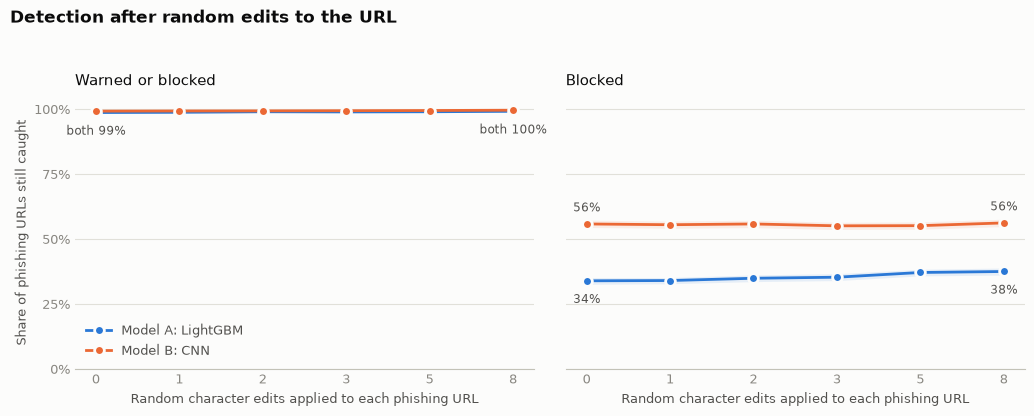

In [17]:
rb = metrics["robustness"]
table = pd.DataFrame({
    (m["label"], point): {p["strength"]: E.fmt({"value": p["recall"], "ci_low": p["ci_low"], "ci_high": p["ci_high"]})
                          for p in m[point]}
    for m in rb["models"].values() for point in ("warn", "block")
})
table.index.name = "random edits"
display(table)
E.plot_robustness(rb, E.FIGURES_DIR / "04_robustness.png");

def edits(name, point, k):
    return next(p["recall"] for p in rb["models"][name][point] if p["strength"] == k)

flat = all(edits(n, p, 8) >= edits(n, p, 0) - 0.02 for n in ("lgbm", "cnn") for p in ("warn", "block"))
display(Markdown(
    f"Blocked after 0 and after 8 random edits: Model A {edits('lgbm', 'block', 0):.1%} and {edits('lgbm', 'block', 8):.1%}; "
    f"Model B {edits('cnn', 'block', 0):.1%} and {edits('cnn', 'block', 8):.1%}. "
    + ("**Random edits did not lower detection. That is not evidence of robustness.** Random edits make a URL look more random, "
       "which these models already treat as suspicious. The test says nothing about edits chosen to look legitimate, such as "
       "changing the path, which section 9.4 shows is the feature Model A leans on most."
       if flat else "**Detection falls as edits are added.**")
))

## 9. Charts

### 9.1 Models and datasets compared

ROC-AUC is used for the comparison chart because it does not depend on a dataset's class mix, so bars can be compared across datasets. 0.5 is chance.

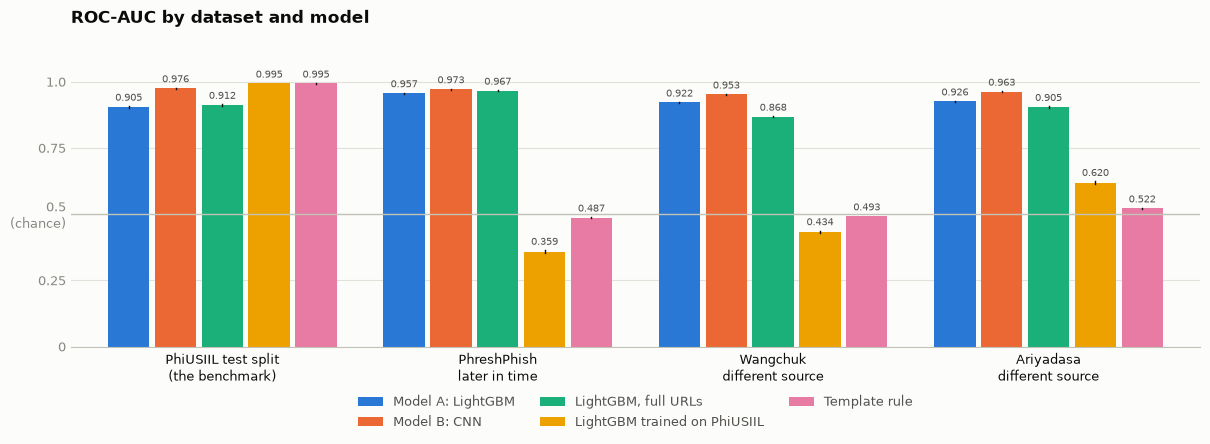

In [18]:
E.plot_model_comparison(R, {"phiusiil_test": "PhiUSIIL test split\n(the benchmark)", "phreshphish_eval": "PhreshPhish\nlater in time",
                            "wangchuk": "Wangchuk\ndifferent source", "ariyadasa": "Ariyadasa\ndifferent source"},
                        E.FIGURES_DIR / "04_model_comparison.png");

### 9.2 ROC and precision-recall curves

The ROC panels use a logarithmic false-positive axis, because the region that matters operationally is the far left (0.1% and below). The template rule is a single point: it has one operating point, not a curve.

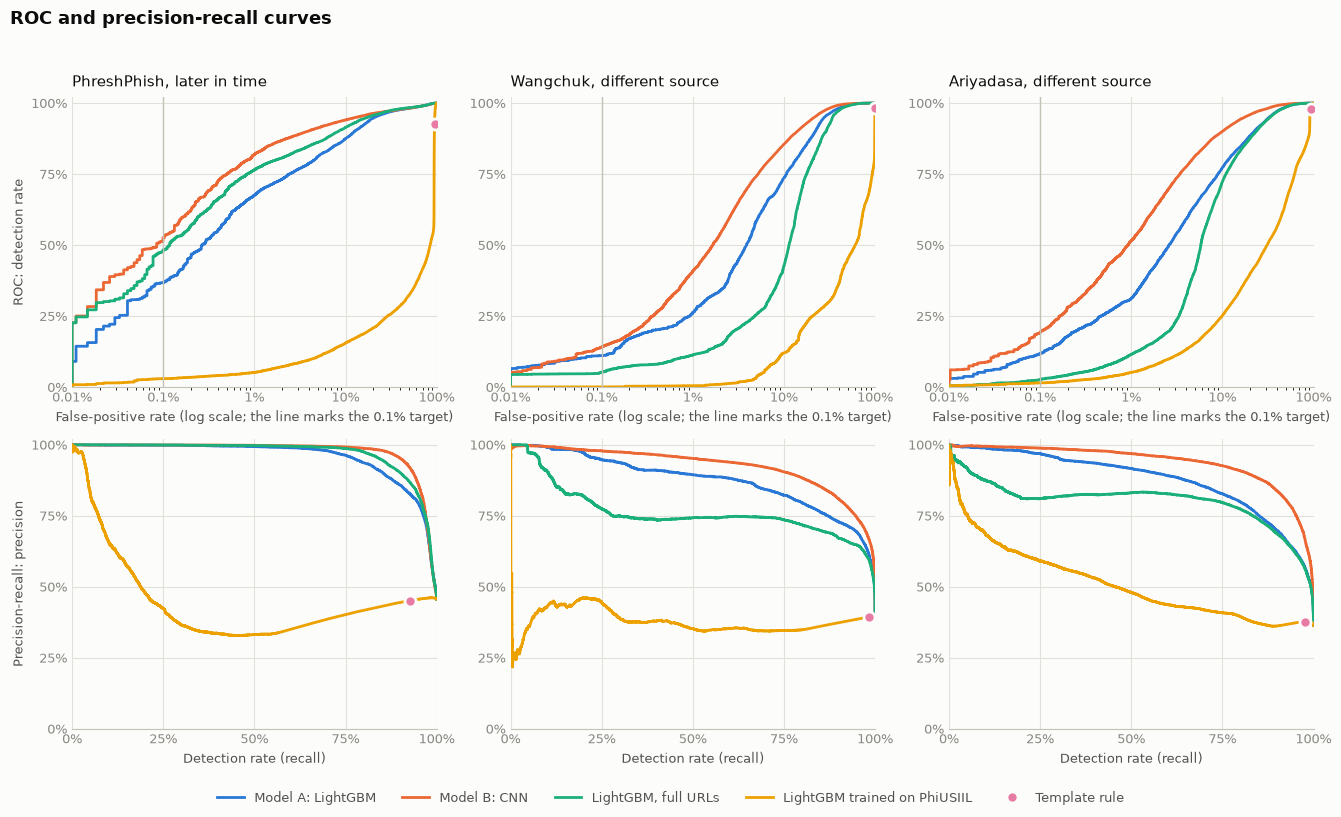

In [19]:
scored = {key: (frames[key]["label"].to_numpy(), scores[key]) for key in MAIN}
E.plot_curves(scored, MAIN, E.FIGURES_DIR / "04_roc_pr_curves.png");

### 9.3 Verdicts by true class

What the app would have said for every URL in each test set, using the frozen thresholds. Each row sums to 100%.

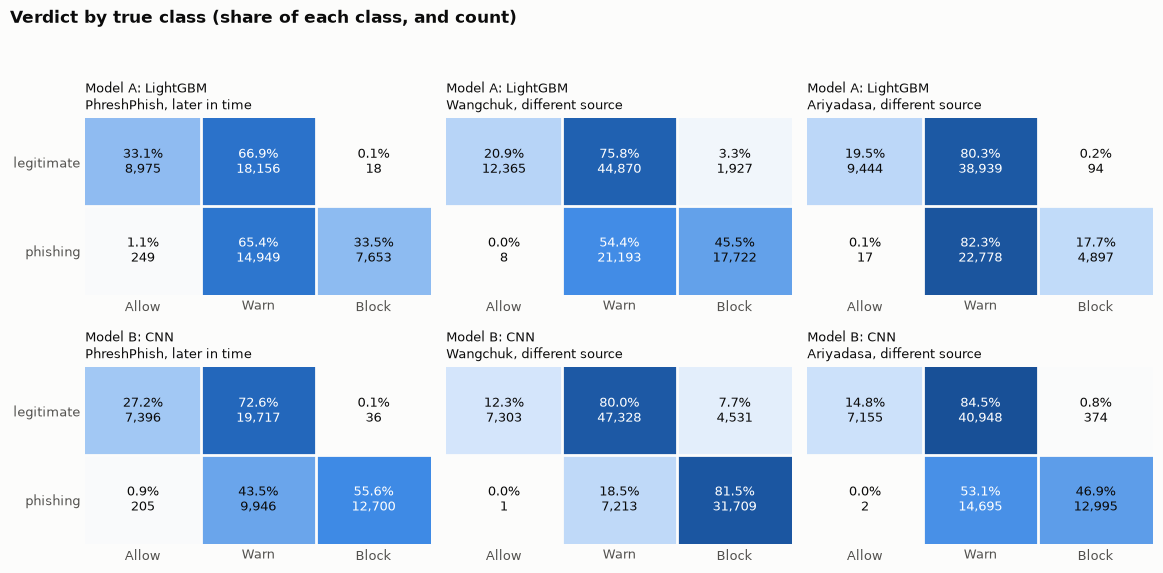

In [20]:
E.plot_confusion(R, MAIN, E.FIGURES_DIR / "04_confusion_matrices.png");

### 9.4 What drives Model A's scores

SHAP values break each score into per-feature contributions. Each dot is one URL from a random sample of 5,000 evaluation-sample URLs; its position is how far that feature pushed the score towards phishing (right) or legitimate (left), and its colour is the feature's value. The app shows the same kind of breakdown for a single URL, computed by LightGBM itself.

,mean_abs_shap
feature,
path_len,1.557
tld_is_common,1.212
host_len,0.458
n_host_hyphens,0.381
host_entropy,0.377
subdomain_depth,0.372
path_depth,0.369
url_entropy,0.315
tld_is_cc,0.311


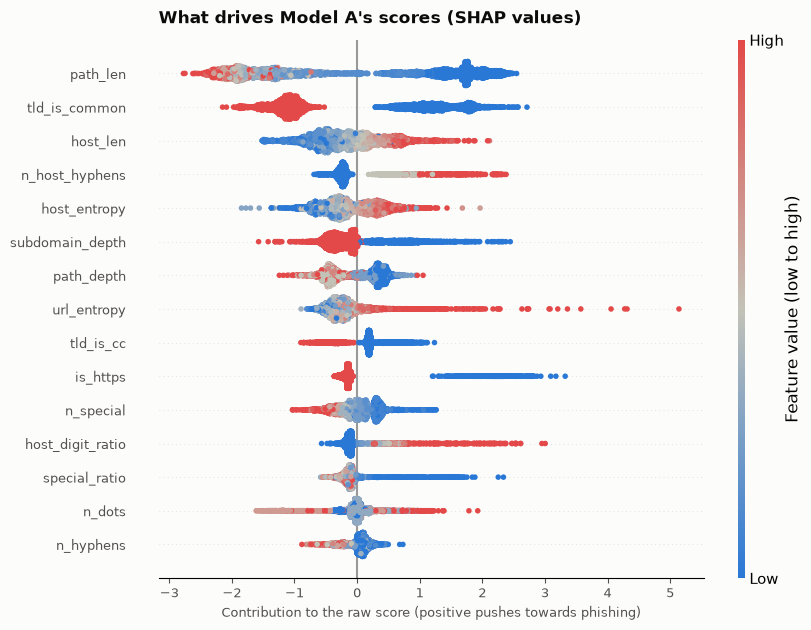

In [21]:
sample = frames["phreshphish_eval"].sample(5000, random_state=D.SEED)
_, shap_order = E.plot_shap_summary(M.load_lgbm(M.MODELS_DIR / "lgbm.txt"), M.lexical_features(sample, "main"),
                                    E.FIGURES_DIR / "04_shap_summary.png")
metrics["shap_mean_abs_by_feature"] = shap_order
E.write_metrics(metrics)
pd.DataFrame(shap_order).head(10).set_index("feature").style.format("{:.3f}")

## 10. Reference scores for the deployed app

The app must give exactly the scores this notebook gives. A small set of **invented** URLs is scored here and saved to `reports/app_reference_scores.json`; a test then runs the same URLs through the app's own code and requires the same raw scores, calibrated scores and verdicts.

In [22]:
reference_urls = [
    "https://www.example.com", "https://www.example.com/", "example.org/about/team",
    "https://docs.example.net/guides/getting-started/installation.html",
    "https://shop.example.com/products/item-48213?ref=newsletter&utm_source=mail",
    "http://secure-login.account-verify.example.top/signin/",
    "http://paypal.com.account-check.example.xyz/verify/login.php?session=8f2a",
    "https://xn--pypal-4ve.example/", "http://192.0.2.44/wp-admin/update/index.html",
    "https://storage.example.dev/ipfs/bafybeigdyrztexample/index.html",
    "https://sites.example.app/view/microsoft-office365-reset", "HTTPS://WWW.Example.ORG/News/2025/Article?id=7#comments",
    "https://university.example.edu/admissions/apply", "http://bit.example/3xYz9", "https://a.b.c.d.e.example.co.uk/x/y/z",
    "https://example.com/" + "a" * 250, "ftp://files.example.com/pub/readme.txt", "https://user@login.example.com:8443/auth",
    "https://www.wikipedia.example/wiki/Phishing", "http://free-gift-card-winner.example.click/claim-now",
]
ref = pd.DataFrame({"url_raw": reference_urls})
ref["url"] = ref["url_raw"].map(lambda u: F.normalize_url(u, strip_query=F.MAIN_STRIP_QUERY))
ref["url_full"] = ref["url_raw"].map(F.normalize_url)
rows = []
for i, row in ref.iterrows():
    entry = {"url": row["url_raw"], "main_track_url": row["url"]}
    for name in ("lgbm", "cnn"):
        raw = float(scorers[name]["raw"](ref.iloc[[i]])[0])
        entry[name] = {"raw_score": raw,
                       "calibrated_score": float(M.apply_calibration(scorers[name]["operating"]["calibration"], [raw])[0]),
                       "verdict": str(M.verdicts([raw], scorers[name]["operating"]["thresholds"])[0])}
    rows.append(entry)
E.write_json({"note": "Invented URLs on reserved example domains, scored by the frozen models in notebook 04.",
              "urls": rows}, E.REPORTS_DIR / "app_reference_scores.json")
pd.DataFrame([{"url": r["url"][:70], "LightGBM": r["lgbm"]["calibrated_score"], "LightGBM verdict": r["lgbm"]["verdict"],
               "CNN": r["cnn"]["calibrated_score"], "CNN verdict": r["cnn"]["verdict"]} for r in rows]).style.format(
    {"LightGBM": "{:.3f}", "CNN": "{:.3f}"})

,url,LightGBM,LightGBM verdict,CNN,CNN verdict
0,https://www.example.com,0.193,Warn,0.088,Warn
1,https://www.example.com/,0.193,Warn,0.088,Warn
2,example.org/about/team,0.101,Warn,0.088,Warn
3,https://docs.example.net/guides/getting-started/installation.html,0.082,Warn,0.114,Warn
4,https://shop.example.com/products/item-48213?ref=newsletter&utm_source,0.082,Warn,0.088,Warn
5,http://secure-login.account-verify.example.top/signin/,0.983,Block,0.997,Block
6,http://paypal.com.account-check.example.xyz/verify/login.php?session=8,0.988,Block,0.997,Block
7,https://xn--pypal-4ve.example/,0.809,Warn,0.919,Warn
8,http://192.0.2.44/wp-admin/update/index.html,0.983,Block,0.997,Block
9,https://storage.example.dev/ipfs/bafybeigdyrztexample/index.html,0.681,Warn,0.997,Block


## 11. Written results and conclusion

`reports/results.md` is generated from `reports/metrics.json`, so every number in it comes from the saved file. It opens with what the models cannot be trusted to do.

In [23]:
report.write_results_md()

def both(key, metric, digits=3, pct=False):
    a, b = val(key, "lgbm", metric), val(key, "cnn", metric)
    return f"{a:.{digits}%} and {b:.{digits}%}" if pct else f"{a:.{digits}f} and {b:.{digits}f}"

display(Markdown(
    f"- **The models rank URLs well on data they never saw.** ROC-AUC for Model A and Model B: "
    f"{both('phreshphish_eval', 'roc_auc')} on later PhreshPhish data, {both('wangchuk', 'roc_auc')} on Wangchuk and "
    f"{both('ariyadasa', 'roc_auc')} on Ariyadasa.\n"
    f"- **The benchmark-trained baseline does not.** It scores {val('phiusiil_test', 'lgbm_phiusiil', 'roc_auc'):.3f} on "
    f"PhiUSIIL's own test split and {val('phreshphish_eval', 'lgbm_phiusiil', 'roc_auc'):.3f} on later PhreshPhish data, "
    "where 0.5 is chance.\n"
    f"- **Neither model can block on its own.** At the frozen block threshold they block "
    f"{both('phreshphish_eval', 'block_recall', 1, True)} of later phishing, and the false-positive rate that holds on "
    f"later PhreshPhish data ({both('phreshphish_eval', 'block_fpr', 2, True)}) rises on Wangchuk "
    f"({both('wangchuk', 'block_fpr', 2, True)}).\n"
    "- **Random edits did not lower detection**, which says nothing about edits chosen to look legitimate; "
    "notebook 05 tests those.\n\n"
    "The full write-up, with every interval, is `reports/results.md`."
))

- **The models rank URLs well on data they never saw.** ROC-AUC for Model A and Model B: 0.957 and 0.973 on later PhreshPhish data, 0.922 and 0.953 on Wangchuk and 0.926 and 0.963 on Ariyadasa.
- **The benchmark-trained baseline does not.** It scores 0.995 on PhiUSIIL's own test split and 0.359 on later PhreshPhish data, where 0.5 is chance.
- **Neither model can block on its own.** At the frozen block threshold they block 33.5% and 55.6% of later phishing, and the false-positive rate that holds on later PhreshPhish data (0.07% and 0.13%) rises on Wangchuk (3.26% and 7.66%).
- **Random edits did not lower detection**, which says nothing about edits chosen to look legitimate; notebook 05 tests those.

The full write-up, with every interval, is `reports/results.md`.